Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Removed 0 old random-chip files.
Chips written: 40 x 5 files = 200
Every folder holds exactly 40 chips, one set only.
Chips with non-finite radar pixels: 0
s1_pre VH (dB): 1st pct -32.6, median -17.5, 99th pct -11.5  (sensible: about -30 / -17 / -5)
s1_post VH (dB): 1st pct -32.2, median -16.5, 99th pct -10.6  (sensible: about -30 / -17 / -5)
Chips whose flood % differs from the GEE number by more than 2.0 points: 2
          chip_id      group  flood_pct_gee  flood_pct_cut  flood_diff_pp
H_88.4425_21.9515 flood-rich          24.12          22.03          -2.09
H_88.6683_22.1806 flood-rich          15.65          10.30          -5.35
Flood km2 in these chips (cut): 20.4


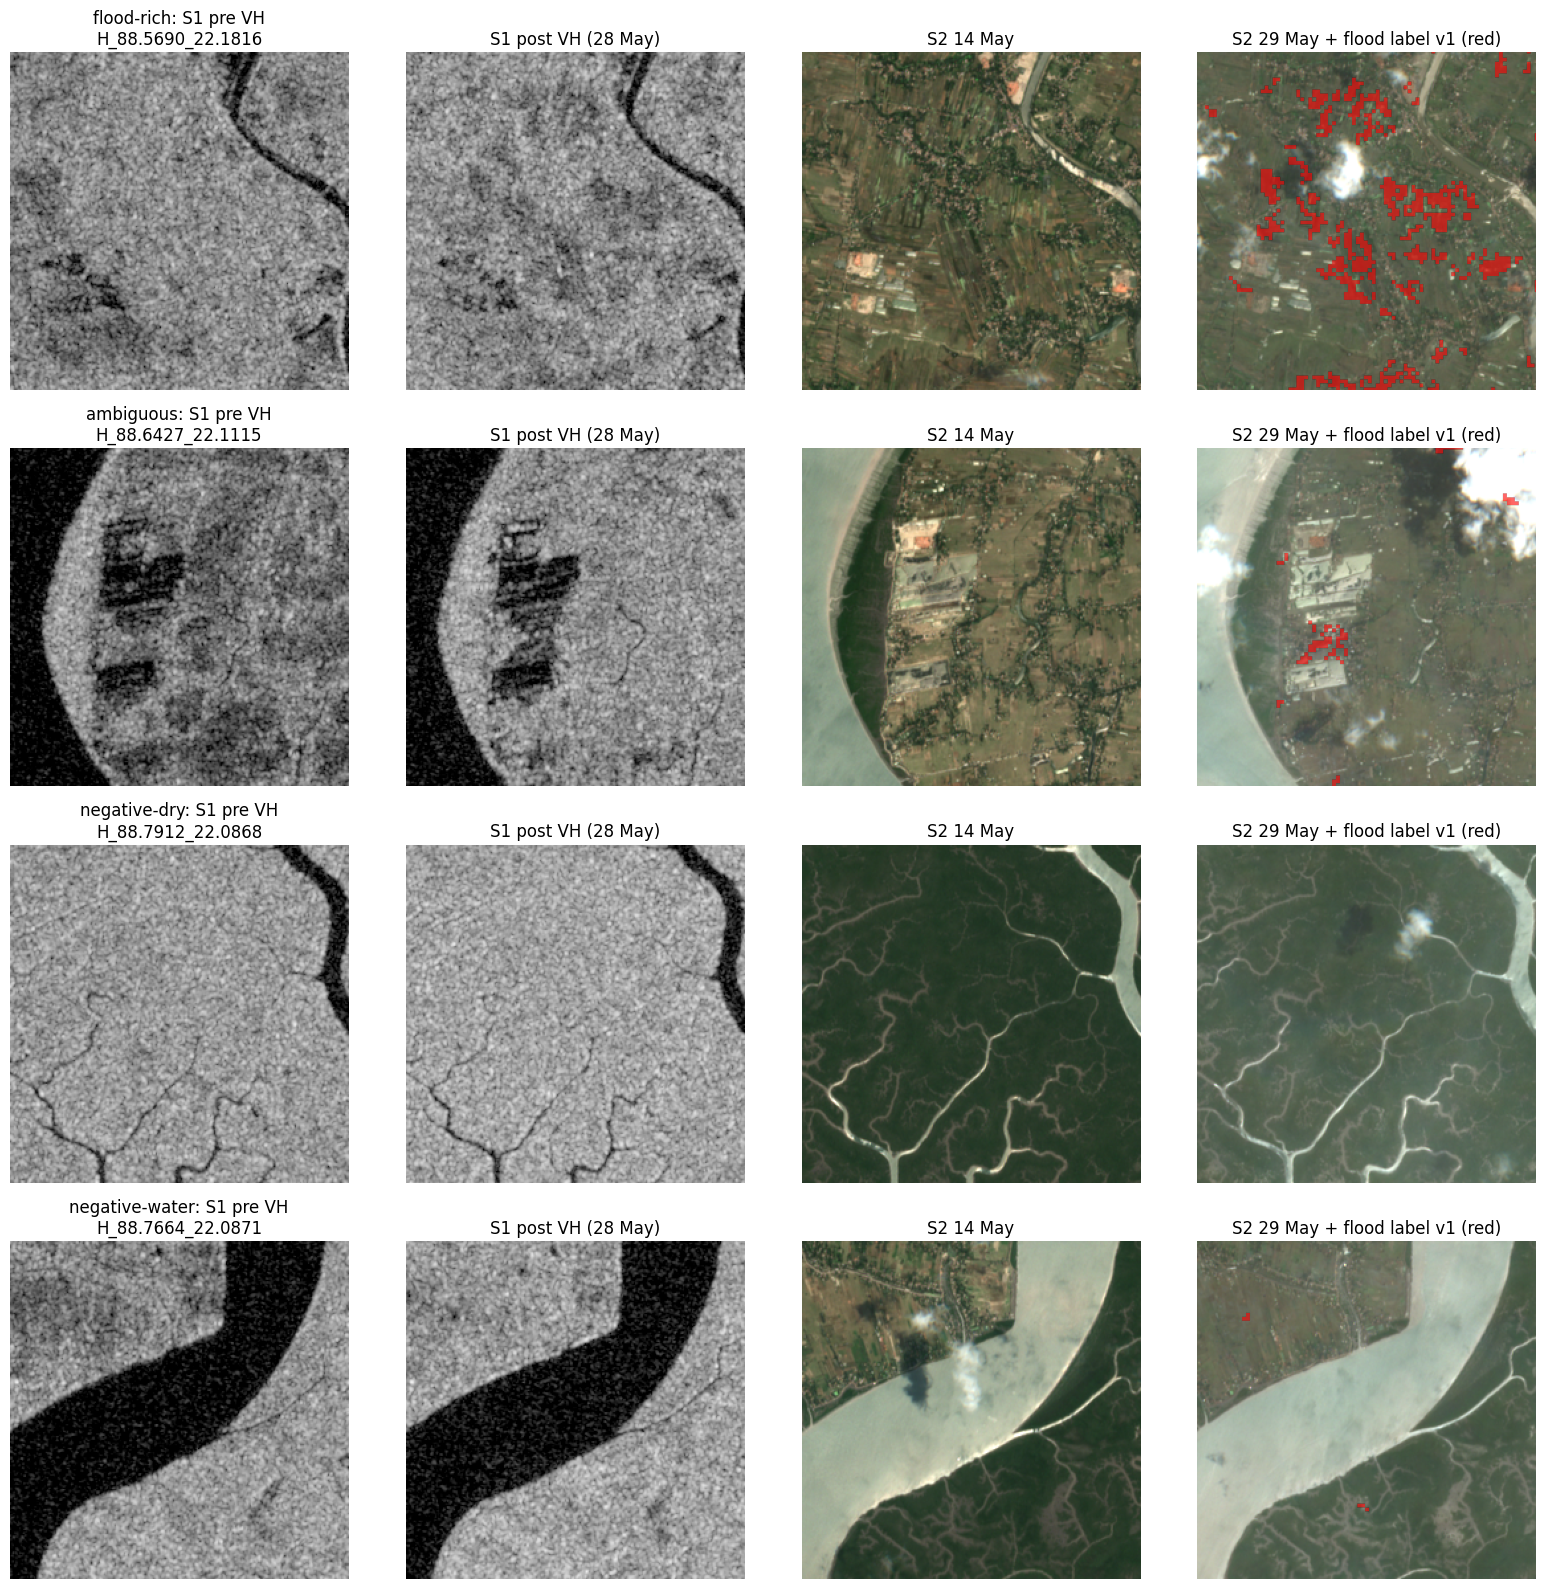

In [ ]:
# ===== FRESH CHIP EXTRACTION: the 40 frozen chips, 256 x 256 pixels at 10 m =====
# One self-contained Colab cell. The chip list is inside, so no CSV is needed.
# Output goes to ONE folder (OUT_DIR), and the old random chips in it are removed first.

!pip install -q rasterio pandas numpy matplotlib

from google.colab import drive
drive.mount('/content/drive')

import os
import re
from io import StringIO
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window, bounds as window_bounds, transform as window_transform
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.warp import transform as warp_transform
from contextlib import ExitStack
import matplotlib.pyplot as plt

# ----- Paths: edit these two if yours differ -----
BASE_DIR = "/content/drive/MyDrive/flood_mapping/Bengal_Dataset"                       # the five exported rasters
OUT_DIR = "/content/drive/MyDrive/flood_mapping/Bengal_Dataset/chips"          # same folder as the earlier notebook

CLEAN_OLD = True       # delete the earlier random chips (chip_001_*.tif ... and chip_manifest.csv) first

# ----- Fixed by the chip selection script -----
CHIP_PX = 256          # 256 x 256 pixels at 10 m = 2,560 m
CELL_M = 2560          # chip cells sit on a 2,560 m grid in UTM 45N (EPSG:32645)
EPSG = "EPSG:32645"
FLOOD_TOLERANCE_PP = 2.0   # warn if flood % differs from the GEE number by more than this

FILES = {
    "s1_pre":  os.path.join(BASE_DIR, "bengal_H_pre_20200516_s1.tif"),
    "s1_post": os.path.join(BASE_DIR, "bengal_H_post_20200528_s1.tif"),
    "s2_pre":  os.path.join(BASE_DIR, "bengal_H_s2_20200514.tif"),
    "s2_post": os.path.join(BASE_DIR, "bengal_H_s2_20200529.tif"),
    "labels":  os.path.join(BASE_DIR, "bengal_H_labels_v1_30m.tif"),
}
# Label file bands: 1 flood_v1, 2 clear, 3 already_water, 4 s2_new_water, 5 dark_before
# S2 file bands:   1 B2 (blue), 2 B3 (green), 3 B4 (red), 4 B11 (SWIR)   <- NOT in R, G, B order

# ----- The frozen chip list (chips_selected.csv) -----
CHIPS_CSV = """
chip_id,group,quadrant,lon,lat,flood_pct,flood_km2,clear_pct,water_pct,amb_score
H_88.5690_22.1816,flood-rich,NW,88.5690,22.1816,9.84,0.645,66,2,0.341
H_88.8417_22.1556,flood-rich,NE,88.8417,22.1556,20.80,1.363,61,19,0.430
H_88.4425_21.9515,flood-rich,SW,88.4425,21.9515,24.12,1.581,57,6,0.383
H_88.5943_22.2276,flood-rich,NW,88.5943,22.2276,4.51,0.296,76,2,0.508
H_88.6683_22.1806,flood-rich,NE,88.6683,22.1806,15.65,1.026,66,67,0.214
H_88.4428_21.9746,flood-rich,SW,88.4428,21.9746,20.09,1.317,59,7,0.390
H_88.5920_22.0195,flood-rich,NW,88.5920,22.0195,4.46,0.293,99,3,0.248
H_88.7927_22.2024,flood-rich,NE,88.7927,22.2024,11.60,0.760,90,1,0.603
H_88.5941_22.2044,flood-rich,NW,88.5941,22.2044,14.99,0.983,30,1,0.370
H_88.8659_22.1091,flood-rich,NE,88.8659,22.1091,13.23,0.867,6,4,0.530
H_88.4177_21.9517,flood-rich,SW,88.4177,21.9517,21.26,1.393,31,1,0.317
H_88.6186_22.1811,flood-rich,NW,88.6186,22.1811,14.76,0.967,49,2,0.385
H_88.8662_22.1322,flood-rich,NE,88.8662,22.1322,11.45,0.751,0,7,0.477
H_88.4175_21.9286,flood-rich,SW,88.4175,21.9286,18.61,1.220,16,4,0.279
H_88.6435_22.1808,flood-rich,NW,88.6435,22.1808,14.72,0.964,32,8,0.468
H_88.7427_22.1798,flood-rich,NE,88.7427,22.1798,10.78,0.706,4,1,0.524
H_88.4423_21.9284,flood-rich,SW,88.4423,21.9284,15.94,1.045,50,7,0.250
H_88.6192_22.2273,flood-rich,NW,88.6192,22.2273,12.59,0.825,25,3,0.558
H_88.6688_22.2268,flood-rich,NE,88.6688,22.2268,9.84,0.645,39,11,0.511
H_88.4180_21.9748,flood-rich,SW,88.4180,21.9748,14.78,0.969,18,1,0.341
H_88.6427_22.1115,ambiguous,NW,88.6427,22.1115,0.89,0.058,56,28,0.470
H_88.8178_22.2252,ambiguous,NE,88.8178,22.2252,1.77,0.116,100,6,0.618
H_88.4168_21.8592,ambiguous,SW,88.4168,21.8592,1.42,0.093,68,2,0.687
H_88.4931_22.0435,ambiguous,NW,88.4931,22.0435,2.31,0.152,53,2,0.282
H_88.5444_22.2049,ambiguous,NW,88.5444,22.2049,0.00,0.000,8,0,0.592
H_88.7185_22.2263,ambiguous,NE,88.7185,22.2263,6.43,0.421,24,1,0.612
H_88.4166_21.8361,ambiguous,SW,88.4166,21.8361,1.26,0.083,100,3,0.677
H_88.6440_22.2271,ambiguous,NW,88.6440,22.2271,11.20,0.734,39,28,0.570
H_88.7930_22.2255,ambiguous,NE,88.7930,22.2255,3.91,0.256,87,6,0.595
H_88.4161_21.7899,ambiguous,SW,88.4161,21.7899,5.82,0.381,100,3,0.668
H_88.7912_22.0868,negative-dry,NE,88.7912,22.0868,0.00,0.000,76,3,0.025
H_88.5397_21.7656,negative-dry,SW,88.5397,21.7656,0.00,0.000,94,1,0.047
H_88.7140_21.8564,negative-dry,SE,88.7140,21.8564,0.04,0.003,100,5,0.040
H_88.4437_22.0671,negative-dry,NW,88.4437,22.0671,0.00,0.000,14,1,0.224
H_88.8163_22.1096,negative-dry,NE,88.8163,22.1096,0.00,0.000,33,3,0.023
H_88.5662_21.9272,negative-dry,SW,88.5662,21.9272,0.00,0.000,93,4,0.026
H_88.7664_22.0871,negative-water,NE,88.7664,22.0871,0.03,0.002,100,34,0.124
H_88.5156_21.8352,negative-water,SW,88.5156,21.8352,0.00,0.000,100,88,0.001
H_88.6421_22.0652,negative-water,NW,88.6421,22.0652,0.00,0.000,12,87,0.000
H_88.8647_22.0166,negative-water,NE,88.8647,22.0166,0.00,0.000,98,32,0.015
"""

for name, path in FILES.items():
    assert os.path.exists(path), f"Missing file: {path}"

chips = pd.read_csv(StringIO(CHIPS_CSV.strip()))
assert len(chips) == 40, f"Expected 40 chips, found {len(chips)}"
assert chips["chip_id"].is_unique, "Duplicate chip ids"

folders = {name: os.path.join(OUT_DIR, name) for name in FILES}

# ----- Remove the earlier random chips so only ONE set of chips exists -----
if CLEAN_OLD:
    old_chip = re.compile(r"^chip_\d{3}_.*\.tif$")      # only the old random-chip names, nothing else
    removed = 0
    for folder in folders.values():
        if os.path.isdir(folder):
            for f in os.listdir(folder):
                if old_chip.match(f):
                    os.remove(os.path.join(folder, f))
                    removed += 1
    old_manifest = os.path.join(OUT_DIR, "chip_manifest.csv")
    if os.path.exists(old_manifest):
        os.remove(old_manifest)
    print(f"Removed {removed} old random-chip files.")

for folder in folders.values():
    os.makedirs(folder, exist_ok=True)


def cell_window(lon, lat, ref):
    """Chip centre (lon, lat) -> pixel window on the reference grid."""
    xs, ys = warp_transform("EPSG:4326", EPSG, [lon], [lat])
    ix = round((xs[0] - CELL_M / 2) / CELL_M)
    iy = round((ys[0] - CELL_M / 2) / CELL_M)
    x0, y0 = ix * CELL_M, iy * CELL_M
    x1, y1 = x0 + CELL_M, y0 + CELL_M
    b = ref.bounds
    assert x0 >= b.left and x1 <= b.right and y0 >= b.bottom and y1 <= b.top, \
        f"Chip at {lon}, {lat} falls outside the raster"
    col = (x0 - ref.transform.c) / ref.res[0]
    row = (ref.transform.f - y1) / ref.res[1]
    assert float(col).is_integer() and float(row).is_integer(), "Chip is not aligned to the pixel grid"
    return Window(int(col), int(row), CHIP_PX, CHIP_PX)


manifest = []
with ExitStack() as stack:
    ref = stack.enter_context(rasterio.open(FILES["s1_post"]))
    assert ref.crs.to_string() == EPSG, f"Unexpected CRS {ref.crs}"
    assert ref.res == (10.0, 10.0), f"Unexpected resolution {ref.res}"

    datasets = {}
    for name, path in FILES.items():
        src = stack.enter_context(rasterio.open(path))
        if name == "labels":
            # 30 m labels onto the 10 m grid. Nearest keeps the values 0 and 1.
            datasets[name] = stack.enter_context(WarpedVRT(
                src, crs=ref.crs, transform=ref.transform,
                width=ref.width, height=ref.height,
                resampling=Resampling.nearest))
        else:
            assert (src.width, src.height, src.transform) == (ref.width, ref.height, ref.transform), \
                f"{name} is not on the same grid as s1_post"
            datasets[name] = src

    for _, r in chips.iterrows():
        win = cell_window(r["lon"], r["lat"], ref)
        tfm = window_transform(win, ref.transform)
        data = {}
        for name, ds in datasets.items():
            arr = ds.read(window=win)
            assert arr.shape[1:] == (CHIP_PX, CHIP_PX), f"{name}: bad shape {arr.shape}"
            data[name] = arr
            prof = {
                "driver": "GTiff", "height": CHIP_PX, "width": CHIP_PX,
                "count": arr.shape[0], "dtype": arr.dtype, "crs": ref.crs,
                "transform": tfm, "compress": "deflate",
            }
            with rasterio.open(os.path.join(folders[name], f"{r['chip_id']}_{name}.tif"), "w", **prof) as dst:
                dst.write(arr)

        b = window_bounds(win, ref.transform)
        lab = data["labels"]
        s1_bad = 1 - np.mean([np.isfinite(data["s1_pre"]).all(0).mean(),
                              np.isfinite(data["s1_post"]).all(0).mean()])
        manifest.append({
            "chip_id": r["chip_id"], "group": r["group"], "quadrant": r["quadrant"],
            "col_off": win.col_off, "row_off": win.row_off,
            "xmin": b[0], "ymin": b[1], "xmax": b[2], "ymax": b[3], "crs": EPSG,
            "flood_pct_gee": r["flood_pct"],
            "flood_pct_cut": round(float(lab[0].mean()) * 100, 2),
            "clear_pct_gee": r["clear_pct"],
            "clear_pct_cut": round(float(lab[1].mean()) * 100, 1),
            "s1_nonfinite_pct": round(float(s1_bad) * 100, 3),
        })

m = pd.DataFrame(manifest)
m["flood_diff_pp"] = (m["flood_pct_cut"] - m["flood_pct_gee"]).round(2)
m.to_csv(os.path.join(OUT_DIR, "chip_manifest.csv"), index=False)

# ----- Checks -----
print("Chips written:", len(m), "x", len(FILES), "files =", len(m) * len(FILES))
for name, folder in folders.items():
    n = len([f for f in os.listdir(folder) if f.endswith(".tif")])
    assert n == 40, f"{name}: {n} files, expected 40 (old chips still there? set CLEAN_OLD = True)"
print("Every folder holds exactly 40 chips, one set only.")
print("Chips with non-finite radar pixels:", int((m["s1_nonfinite_pct"] > 0).sum()))
for name in ["s1_pre", "s1_post"]:
    vals = []
    for cid in m["chip_id"]:
        with rasterio.open(os.path.join(folders[name], f"{cid}_{name}.tif")) as s:
            vals.append(s.read(2).ravel())          # band 2 = VH
    vh = np.concatenate(vals)
    p1, p50, p99 = np.nanpercentile(vh, [1, 50, 99])
    print(f"{name} VH (dB): 1st pct {p1:.1f}, median {p50:.1f}, 99th pct {p99:.1f}  (sensible: about -30 / -17 / -5)")
off = m[m["flood_diff_pp"].abs() > FLOOD_TOLERANCE_PP]
print(f"Chips whose flood % differs from the GEE number by more than {FLOOD_TOLERANCE_PP} points:", len(off))
if len(off):
    print(off[["chip_id", "group", "flood_pct_gee", "flood_pct_cut", "flood_diff_pp"]].to_string(index=False))
print("Flood km2 in these chips (cut):", round((m["flood_pct_cut"] / 100 * 6.5536).sum(), 1))

# ----- Preview: one chip per group, with the correct band order -----
def rgb(arr):   # file bands are B2, B3, B4, B11, so red = band 3, green = band 2, blue = band 1
    return np.clip(arr[[2, 1, 0]].transpose(1, 2, 0) / 3000.0, 0, 1)

groups = ["flood-rich", "ambiguous", "negative-dry", "negative-water"]
fig, axes = plt.subplots(len(groups), 4, figsize=(16, 4 * len(groups)))
for i, g in enumerate(groups):
    row = m[m["group"] == g].iloc[0]
    cid = row["chip_id"]
    def read(name):
        with rasterio.open(os.path.join(folders[name], f"{cid}_{name}.tif")) as s:
            return s.read()
    pre, post = read("s1_pre"), read("s1_post")
    s2a, s2b, lab = read("s2_pre"), read("s2_post"), read("labels")
    axes[i, 0].imshow(pre[1], cmap="gray", vmin=-30, vmax=-5)
    axes[i, 0].set_title(f"{g}: S1 pre VH\n{cid}")
    axes[i, 1].imshow(post[1], cmap="gray", vmin=-30, vmax=-5)
    axes[i, 1].set_title("S1 post VH (28 May)")
    axes[i, 2].imshow(rgb(s2a)); axes[i, 2].set_title("S2 14 May")
    axes[i, 3].imshow(rgb(s2b))
    axes[i, 3].imshow(np.ma.masked_where(lab[0] == 0, lab[0]), cmap="autumn", alpha=0.6)
    axes[i, 3].set_title("S2 29 May + flood label v1 (red)")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()